# Madrid (EMT) — Network Maps for the Electrification Model

Two maps built from our Madrid model output (`outputs/File_2.csv`) and the EMT GTFS feed:

1. **Energy per bus per day by line.** Thick lines are the ones our model sends to **opportunity (terminus) charging** because they need more than about 400 kWh per bus per day.
2. **Lines by operating depot**, with the overnight grid power each depot needs (MW).
3. **Before and after the La Elipa rebuild**: what running La Elipa's lines from Fuencarral costs in grid power and empty km.

They're the Madrid counterparts of the Brussels map in `../Brussels/brussels_benchmark_full.ipynb`.

**Depot locations:** Fuencarral and Carabanchel come from GTFS stops named "Cocheras EMT". La Elipa, Entrevías and Sanchinarro are placed at the nearest named stop in their area and are **approximate** (shown as hollow squares).

In [1]:
# ===================== INPUTS =====================
GTFS   = "data/GTFS.zip"
FILE2  = "outputs/File_2.csv"
OUT    = "outputs"
SERVICE_IDS = ["LA", "LJ"]   # weekday services in the EMT feed (LA and LJ cover different lines)
NIGHT_HOURS = 6.4            # overnight charging window (from the Brussels benchmark notebook)
LOSS_FACTOR = 1.10
# Depot location = a named GTFS stop; exact=True when the stop name says "Cocheras EMT"
DEPOTS = {
    "Fuencarral":  ("Mauricio Legendre - Cocheras Emt", True),
    "Carabanchel": ("Avenida De Los Poblados - Cocheras Emt", True),
    "La Elipa":    ("Santa Irene - Trece Rosas", False),
    "Entrevías":   ("Avenida De Entrevías - La Serena", False),
    "Sanchinarro": ("Sanchinarro", False),
}
# ==================================================

import os, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D

os.makedirs(OUT, exist_ok=True)
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6"]   # validated categorical slots
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "font.size": 10, "legend.frameon": False,
})

## 1. Load model results, line geometry and depot locations

In [2]:
f2 = pd.read_csv(FILE2, dtype={"line_id": str}).set_index("line_id")

z = zipfile.ZipFile(GTFS)
rd = lambda name, **kw: pd.read_csv(z.open(name), dtype=str, **kw)
routes, trips, stops = rd("routes.txt"), rd("trips.txt"), rd("stops.txt")
stops = stops.astype({"stop_lat": float, "stop_lon": float})
trips = trips.merge(routes[["route_id", "route_short_name"]], on="route_id")
wk = trips[trips.service_id.isin(SERVICE_IDS)]

# one representative shape per line: the most used on weekdays
line_shape = wk.groupby("route_short_name").shape_id.agg(lambda x: x.value_counts().index[0])
shp = rd("shapes.txt").astype({"shape_pt_lat": float, "shape_pt_lon": float, "shape_pt_sequence": int}) \
                      .sort_values(["shape_id", "shape_pt_sequence"])
geo = dict(tuple(shp[shp.shape_id.isin(line_shape.values)].groupby("shape_id")))

lines = f2.join(line_shape.rename("shape_id"), how="inner")
print(f"Lines in model: {len(f2)} | with geometry: {len(lines)}")

dep = pd.DataFrame({k: {**stops[stops.stop_name == v].iloc[0][["stop_lat", "stop_lon"]].to_dict(), "exact": ex}
                    for k, (v, ex) in DEPOTS.items()}).T
dep["mwh_day"] = (f2.energy_kwh_bus_day * f2.peak_buses).groupby(f2.depot_name).sum() / 1000
dep["buses"] = f2.groupby("depot_name").peak_buses.sum()
dep["mw_needed"] = dep.mwh_day / NIGHT_HOURS * LOSS_FACTOR
dep.round(1)

Lines in model: 234 | with geometry: 234


,stop_lat,stop_lon,exact,mwh_day,buses,mw_needed
Fuencarral,40.47994,-3.68359,True,96.3,477,16.6
Carabanchel,40.37345,-3.72715,True,93.6,455,16.1
La Elipa,40.41849,-3.65006,False,65.3,287,11.2
Entrevías,40.37885,-3.6653,False,82.7,399,14.2
Sanchinarro,40.48602,-3.64658,False,109.3,424,18.8


In [3]:
def base_axes(figsize=(10, 10)):
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_aspect(1 / np.cos(np.radians(40.42)))
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(False)
    return fig, ax

def draw_depots(ax, labels):
    for n, r in dep.iterrows():
        ax.scatter(r.stop_lon, r.stop_lat, marker="s", s=120, zorder=6,
                   facecolor=INK if r.exact else "#fcfcfb", edgecolor=INK, lw=2)
        ax.annotate(labels(n, r), (r.stop_lon, r.stop_lat), xytext=(9, -3), textcoords="offset points",
                    fontsize=9, color=INK, zorder=7,
                    bbox=dict(boxstyle="round,pad=0.2", fc="#fcfcfb", ec="none", alpha=0.85))

## 2. Map: energy per bus per day, and where terminus charging is needed

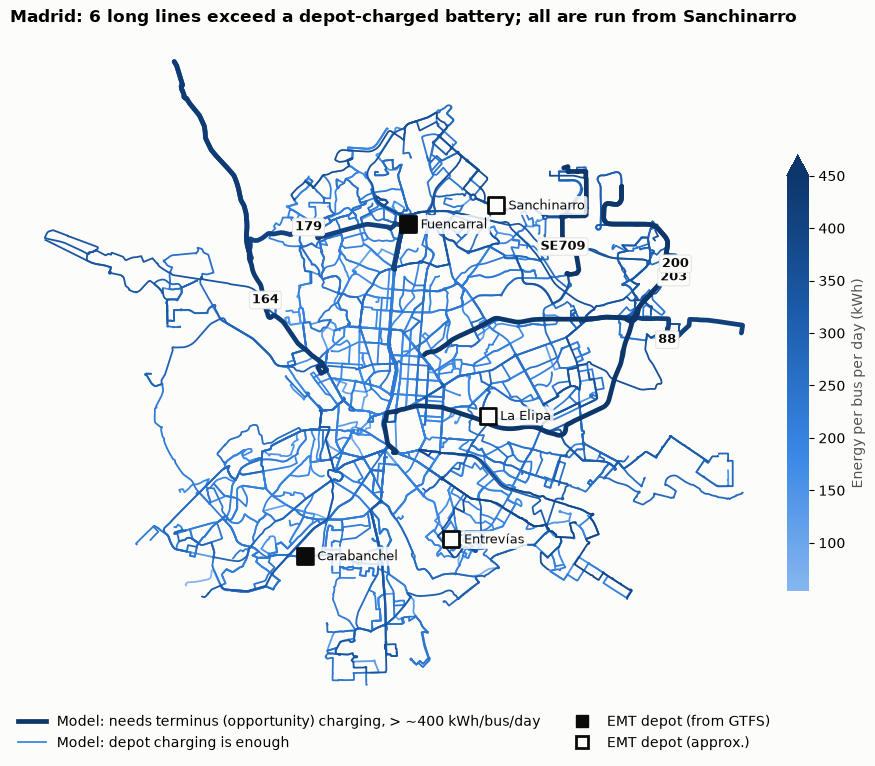

,daily_km,peak_buses,km_per_bus_day,energy_kwh_bus_day,depot_name
line_id,,,,,
203,3192.0,7,456.0,592.8,Sanchinarro
200,2904.3,6,484.0,629.3,Sanchinarro
164,1984.2,6,330.7,429.9,Sanchinarro
179,1246.5,4,311.6,405.1,Sanchinarro
SE709,853.3,2,426.7,554.7,Sanchinarro
88,635.0,2,317.5,412.8,Sanchinarro


In [4]:
cmap = LinearSegmentedColormap.from_list("blue_seq", ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
vmax = 450
norm = Normalize(vmin=lines.energy_kwh_bus_day.min(), vmax=vmax)
opp = lines.charging_strategy == "Opportunity"

fig, ax = base_axes()
for lid, r in lines.sort_values("energy_kwh_bus_day").iterrows():
    g = geo[r.shape_id]
    ax.plot(g.shape_pt_lon, g.shape_pt_lat, lw=3.4 if opp[lid] else 1.3, zorder=3 if opp[lid] else 2,
            color=cmap(norm(min(r.energy_kwh_bus_day, vmax))), solid_capstyle="round")
for lid in lines.index[opp]:
    g = geo[lines.loc[lid, "shape_id"]]
    p = g.iloc[int(len(g) * 0.6)]
    ax.annotate(lid, (p.shape_pt_lon, p.shape_pt_lat), fontsize=9, fontweight="bold", color=INK,
                ha="center", va="center", zorder=8,
                bbox=dict(boxstyle="round,pad=0.2", fc="#fcfcfb", ec=GRID, lw=0.8))
draw_depots(ax, lambda n, r: n)

sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
cb = fig.colorbar(sm, ax=ax, shrink=0.45, pad=0.01, extend="max")
cb.set_label("Energy per bus per day (kWh)", color=INK2); cb.outline.set_visible(False)
ax.legend(handles=[
    Line2D([], [], color="#0d366b", lw=3.4, label="Model: needs terminus (opportunity) charging, > ~400 kWh/bus/day"),
    Line2D([], [], color="#3987e5", lw=1.3, label="Model: depot charging is enough"),
    Line2D([], [], marker="s", ls="", color=INK, ms=9, label="EMT depot (from GTFS)"),
    Line2D([], [], marker="s", ls="", mfc="#fcfcfb", mec=INK, mew=2, ms=9, label="EMT depot (approx.)"),
], loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=2)
n_opp = int(opp.sum())
ax.set_title(f"Madrid: {n_opp} long lines exceed a depot-charged battery; all are run from Sanchinarro")
fig.tight_layout(); fig.savefig(f"{OUT}/fig_madrid_network_energy_map.png", dpi=160); plt.show()

lines.loc[opp, ["daily_km", "peak_buses", "km_per_bus_day", "energy_kwh_bus_day", "depot_name"]].round(1)

## 3. Map: lines by depot, with the overnight grid power each depot needs

> MW needed ≈ depot MWh/day ÷ night charging hours × (1 + losses)

For reference, Carabanchel's real grid connection is **15 MW**, and our model needs ~16 MW there.

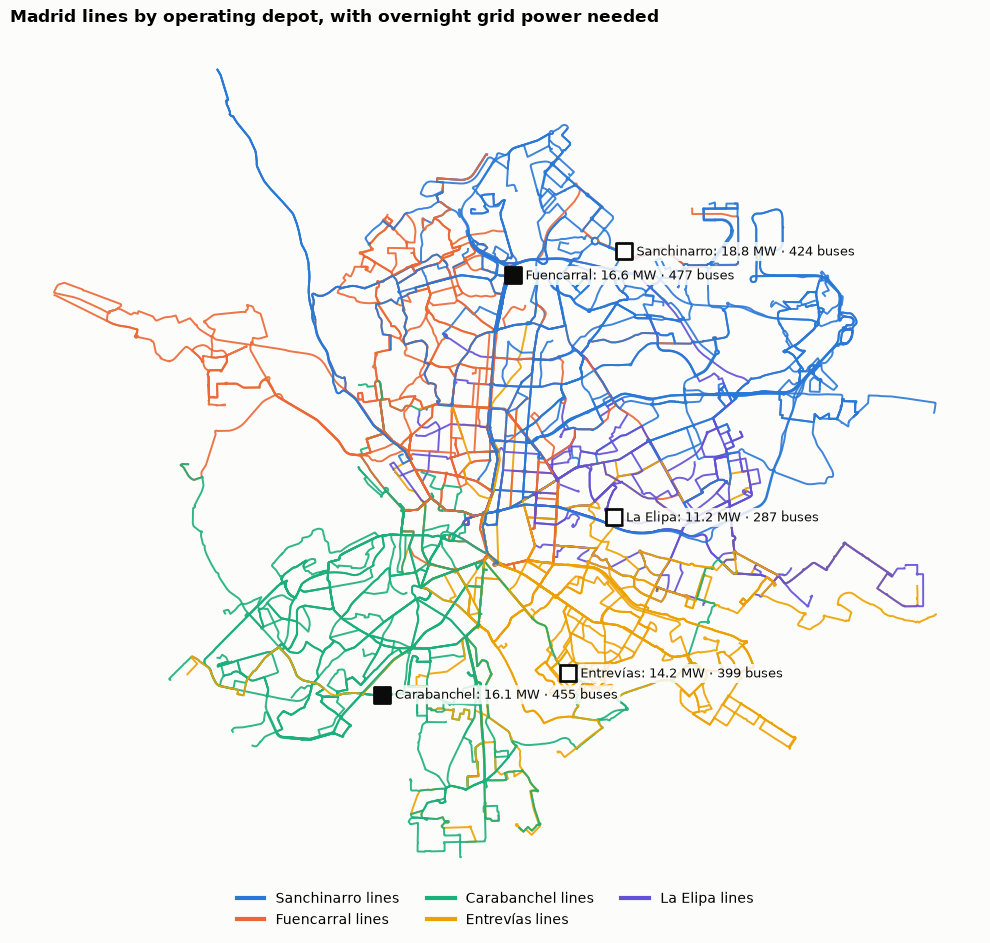

,buses,mwh_day,mw_needed,exact
Sanchinarro,424,109.3,18.8,False
Fuencarral,477,96.3,16.6,True
Carabanchel,455,93.6,16.1,True
Entrevías,399,82.7,14.2,False
La Elipa,287,65.3,11.2,False


In [5]:
order = dep.sort_values("mw_needed", ascending=False).index.tolist()
col = {d: C[i] for i, d in enumerate(order)}

fig, ax = base_axes()
for lid, r in lines.iterrows():
    g = geo[r.shape_id]
    ax.plot(g.shape_pt_lon, g.shape_pt_lat, color=col.get(r.depot_name, "#b4b3ad"), lw=1.4, alpha=0.9, zorder=2)
draw_depots(ax, lambda n, r: f"{n}: {r.mw_needed:.1f} MW · {int(r.buses)} buses")
ax.legend(handles=[Line2D([], [], color=col[d], lw=3, label=f"{d} lines") for d in order],
          loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=3)
ax.set_title("Madrid lines by operating depot, with overnight grid power needed")
fig.tight_layout(); fig.savefig(f"{OUT}/fig_madrid_network_depot_map.png", dpi=160); plt.show()
dep[["buses", "mwh_day", "mw_needed", "exact"]].round(1).sort_values("mw_needed", ascending=False)

## 4. Before and after the La Elipa rebuild

- **Today:** La Elipa has been closed since March 2022. Its 315 buses and 36 day lines operate from **Fuencarral**.
- **After reopening:** EMT tendered the rebuild in June 2026 (€134.3 M, up to 32 months of works), so reopening is likely around **2029**. The new depot is 100% electric with 318 places, 20 of them for articulated buses.

For each case we compute the overnight grid power per depot and the **extra empty km** of driving La Elipa's lines to and from Fuencarral. Empty km = straight-line distance from each bus's first and last stop to its depot × 1.3 for the road network.

In [6]:
# ===================== INPUTS =====================
TEMP_HOST   = "Fuencarral"   # depot hosting La Elipa's lines during the rebuild
ROAD_FACTOR = 1.3
KWH_PER_KM_EMPTY = 1.30      # standard bus, same as the model
REF = "20261117"
# ==================================================

def hav(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

# bus pull-outs: first and last stop of every weekday block, tagged with its model depot
st = rd("stop_times.txt", usecols=["trip_id", "stop_id", "stop_sequence", "departure_time"])
st = st[st.trip_id.isin(wk.trip_id)].astype({"stop_sequence": int}).sort_values(["trip_id", "stop_sequence"])
ends = st.groupby("trip_id").agg(first_stop=("stop_id", "first"), last_stop=("stop_id", "last"),
                                 t0=("departure_time", "first"), t1=("departure_time", "last")).reset_index()
tb = wk.merge(ends, on="trip_id")
tb["depot"] = tb.route_short_name.map(f2.depot_name)
tb = tb.dropna(subset=["depot"])
blk = (tb.sort_values("t0").groupby("block_id").agg(first_stop=("first_stop", "first"), depot=("depot", "first"))
         .join(tb.sort_values("t1").groupby("block_id").last_stop.last()))
xy = stops.set_index("stop_id")[["stop_lat", "stop_lon"]]

def empty_km(blocks, depot_name):
    d = dep.loc[depot_name]
    a, b = xy.loc[blocks.first_stop].values, xy.loc[blocks.last_stop].values
    return (hav(a[:, 0], a[:, 1], d.stop_lat, d.stop_lon) + hav(b[:, 0], b[:, 1], d.stop_lat, d.stop_lon)) * ROAD_FACTOR

elipa_blk = blk[blk.depot == "La Elipa"]
km_after  = empty_km(elipa_blk, "La Elipa").sum()
km_today  = empty_km(elipa_blk, TEMP_HOST).sum()
extra_km  = km_today - km_after

# depot power in both cases
today = dep[["buses", "mwh_day"]].copy()
today.loc[TEMP_HOST] += today.loc["La Elipa"]
today.loc[TEMP_HOST, "mwh_day"] += extra_km * KWH_PER_KM_EMPTY / 1000
today.loc["La Elipa"] = 0
cmp_ = pd.DataFrame({
    "buses today": today.buses.astype(int),
    "MW today": (today.mwh_day / NIGHT_HOURS * LOSS_FACTOR).round(1),
    "buses after": dep.buses.astype(int),
    "MW after": dep.mw_needed.round(1),
}).loc[order]
cmp_.loc["Total"] = cmp_.sum()
cmp_ = cmp_.astype({"buses today": int, "buses after": int})

print(f"La Elipa pull-outs (blocks): {len(elipa_blk)}")
print(f"Empty km per weekday, La Elipa lines: {km_today:,.0f} from {TEMP_HOST} today vs {km_after:,.0f} from La Elipa "
      f"-> {extra_km:,.0f} extra km/day ({extra_km * KWH_PER_KM_EMPTY / 1000:.1f} MWh/day if electric, "
      f"~{extra_km * 255 / 1e6:.2f} M km/year on weekdays)")
cmp_.to_csv(f"{OUT}/madrid_la_elipa_before_after.csv")
cmp_

La Elipa pull-outs (blocks): 308
Empty km per weekday, La Elipa lines: 6,586 from Fuencarral today vs 2,887 from La Elipa -> 3,699 extra km/day (4.8 MWh/day if electric, ~0.94 M km/year on weekdays)


,buses today,MW today,buses after,MW after
Sanchinarro,424,18.8,424,18.8
Fuencarral,764,28.6,477,16.6
Carabanchel,455,16.1,455,16.1
Entrevías,399,14.2,399,14.2
La Elipa,0,0.0,287,11.2
Total,2042,77.7,2042,76.9


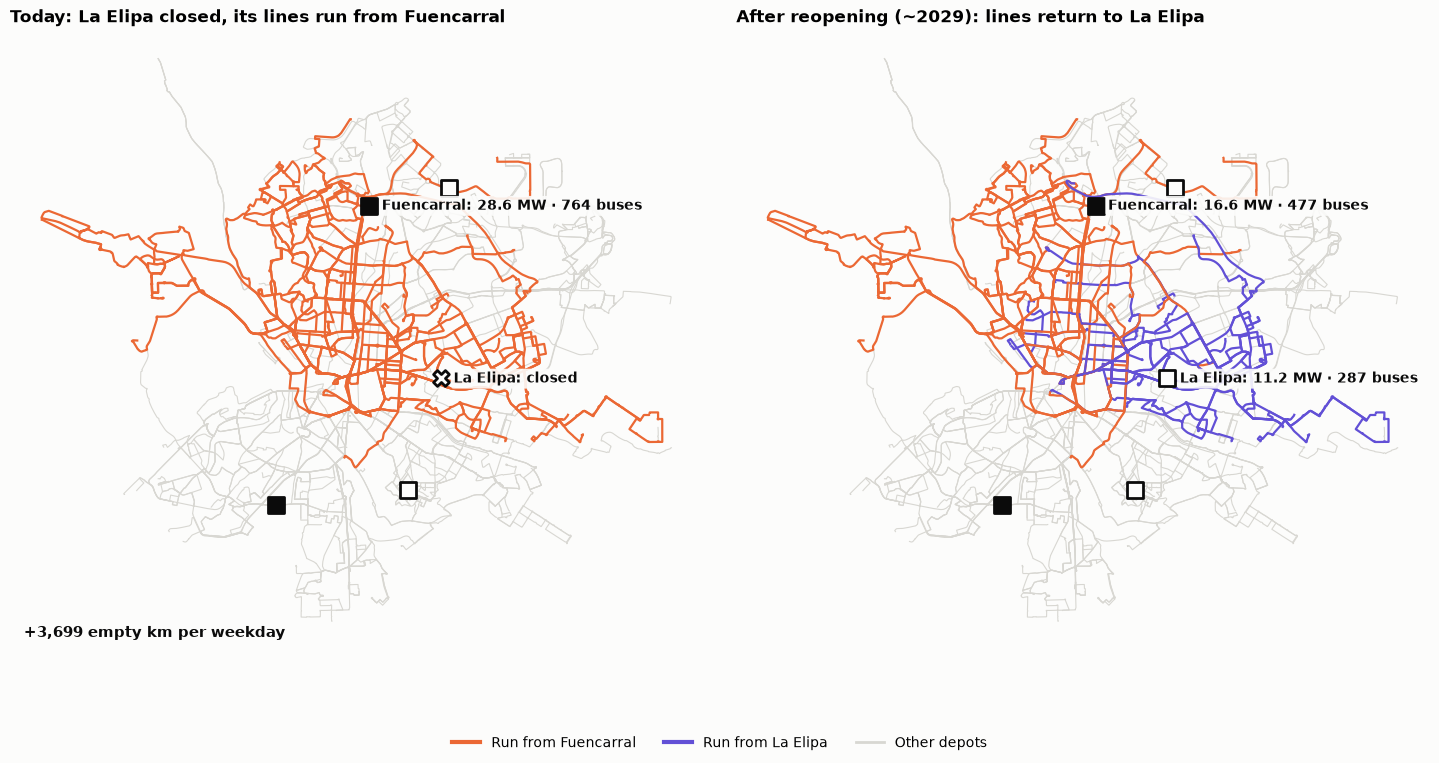

In [7]:
# Side-by-side maps: today (La Elipa lines run from Fuencarral) vs after reopening
fig, axes = plt.subplots(1, 2, figsize=(15, 8))
for ax, case in zip(axes, ["today", "after"]):
    ax.set_aspect(1 / np.cos(np.radians(40.42))); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(False)
    for lid, r in lines.iterrows():
        g = geo[r.shape_id]
        d = r.depot_name
        if case == "today" and d == "La Elipa":
            c_, lw, z_ = col[TEMP_HOST], 1.6, 3
        elif d in ("La Elipa", TEMP_HOST):
            c_, lw, z_ = col[d], 1.6, 3
        else:
            c_, lw, z_ = "#d8d7d2", 0.8, 1
        ax.plot(g.shape_pt_lon, g.shape_pt_lat, color=c_, lw=lw, zorder=z_)
    for n, r in dep.iterrows():
        closed = case == "today" and n == "La Elipa"
        ax.scatter(r.stop_lon, r.stop_lat, marker="X" if closed else "s", s=130, zorder=6,
                   color=INK if (r.exact and not closed) else "#fcfcfb", edgecolor=INK, lw=2)
        if n in ("La Elipa", TEMP_HOST):
            mw = cmp_.loc[n, "MW today" if case == "today" else "MW after"]
            nb = cmp_.loc[n, "buses today" if case == "today" else "buses after"]
            lab = f"{n}: closed" if closed else f"{n}: {mw:.1f} MW · {int(nb)} buses"
            ax.annotate(lab, (r.stop_lon, r.stop_lat), xytext=(9, -3), textcoords="offset points",
                        fontsize=10, color=INK, zorder=7, fontweight="bold",
                        bbox=dict(boxstyle="round,pad=0.2", fc="#fcfcfb", ec="none", alpha=0.9))
    ax.set_title("Today: La Elipa closed, its lines run from Fuencarral" if case == "today"
                 else "After reopening (~2029): lines return to La Elipa")
axes[0].text(0.02, 0.02, f"+{extra_km:,.0f} empty km per weekday", transform=axes[0].transAxes,
             fontsize=11, color=INK, fontweight="bold")
fig.legend(handles=[Line2D([], [], color=col[TEMP_HOST], lw=3, label=f"Run from {TEMP_HOST}"),
                    Line2D([], [], color=col["La Elipa"], lw=3, label="Run from La Elipa"),
                    Line2D([], [], color="#d8d7d2", lw=2, label="Other depots")],
           loc="lower center", ncol=3)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(f"{OUT}/fig_madrid_la_elipa_before_after.png", dpi=160); plt.show()

**Notes**
- **La Elipa** is being rebuilt as a 100% electric depot (318 buses). While works run, its lines operate from Fuencarral. Maps 1–2 show the model's planned assignment; section 4 compares it with today.
- **EMT today charges almost entirely in depots** (automated inverted pantographs). Its only line with terminus charging so far is **line 76** (inductive charging, since 2018). The thick lines on map 1 are where the Brussels approach (pantographs at line terminals) would apply.